**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**01 | OneStop Dataset and Experimental Protocol**

![OneStop Dataset and Experimental Protocol — scientific workflow](../../images/01_onestop_dataset_and_protocol.svg)

**Objective:** Identify ordinary-reading paragraph trials, reconcile the reported outcomes and establish participant-disjoint evaluation.

**Dataset:** The official OneStop ordinary-reading fixation and interest-area reports. Published corpus size is not the retained cohort size.

**Scope:** Acquire the original paragraph reports, reconcile trial outcomes and define participant and article-batch partitions for subsequent analysis.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import (
    RESOURCES, acquire_reports, read_report, make_cohort, make_splits,
)

# ------------------- 7. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "onestop" / "ordinary"
processed = root / "data" / "processed" / "onestop"
processed.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", out_dir)
print("Source directory:", raw_dir)
print("Local data directory:", processed)
print("Python:", sys.version.split()[0])


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/onestop/ordinary
Local data directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/onestop
Python: 3.13.18


**02. Acquire Ordinary-Reading Paragraph Reports**

Reuse the official ordinary-reading reports or download their two ZIP archives from OSF. Only the Paragraph interest period is required; question, answer and feedback eye movements are outside the input boundary.

**Recorded source inventory:** The executed run used the two original CSV reports, approximately 3.00 GB for fixations and 2.46 GB for interest areas (decimal GB). Keep these source files in `data/raw/onestop/ordinary/` for reuse by Notebook 02; they are not part of the derived output ZIP.

In [3]:
# ============== 02. Acquire Ordinary-Reading Paragraph Reports ===============

# ------------------- 1. Acquire or Reuse Original Reports --------------------
reports = acquire_reports(raw_dir)

# --------------------- 2. Summarise Source Availability ----------------------
inventory = pd.DataFrame([{"report": k, "source": f"https://osf.io/download/{RESOURCES[k]}/",
                           "file": p.name, "bytes": p.stat().st_size}
                          for k,p in reports.items()])
display(inventory)


,report,source,file,bytes
0,fixations,https://osf.io/download/ne4az/,fixations_Paragraph.csv,2997905127
1,ia,https://osf.io/download/xkgfz/,ia_Paragraph.csv,2455810901


**03. Inspect Report Schema and Trial Identity**

Read the documented fields. The participant and trial index identify a reading/response trial. Article identifiers are qualified by the article batch; paragraph and question identities preserve that hierarchy. Outcome metadata are used only for cohort selection and scoring.

**Recorded report dimensions:** The fixation report supplied 1,172,718 rows across 18 selected columns; the interest-area report supplied 1,104,883 rows across 20 selected columns. These are report rows, not independent trials or participants.

In [4]:
# =============== 03. Inspect Report Schema and Trial Identity ================

# ---------------- 1. Load Fixation and Interest-Area Reports -----------------
fix = read_report(reports["fixations"], "fixations")
ia = read_report(reports["ia"], "ia")

# ------------------------ 2. Record Report Dimensions ------------------------
inventory["n_rows"] = inventory.report.map({"fixations":len(fix),"ia":len(ia)})
inventory["n_columns_used"] = inventory.report.map({"fixations":fix.shape[1],"ia":ia.shape[1]})
display(inventory)


,report,source,file,bytes,n_rows,n_columns_used
0,fixations,https://osf.io/download/ne4az/,fixations_Paragraph.csv,2997905127,1172718,18
1,ia,https://osf.io/download/xkgfz/,ia_Paragraph.csv,2455810901,1104883,20


**04. Reconcile Eligible Reading Trials**

Retain first ordinary-reading trials with matched report metadata, a valid A–D answer, a documented correctness label and at least one valid fixation. Exclusion counts describe the union of report trial identities, not the full published corpus.

**Recorded cohort:** Of 10,078 distinct trial identities in the report union, 9,718 were eligible and 360 were assigned to `practice_or_unknown`. No other exclusion category was observed in this run. The retained cohort comprises 180 participants and 30 articles; the 9,718 trials are repeated observations within participants and articles.

In [5]:
# =================== 04. Reconcile Eligible Reading Trials ===================

# --------------------- 1. Construct the Eligible Cohort ----------------------
trials, exclusions = make_cohort(fix, ia)

# ---------------- 2. Summarise Trial and Participant Support -----------------
display(exclusions)
print("Eligible trials:", len(trials))
print("Participants:", trials.participant_id.nunique())
print("Articles:", trials.article_key.nunique())
del fix, ia


,disposition,n_trials
0,eligible,9718
1,practice_or_unknown,360


Eligible trials: 9718
Participants: 180
Articles: 30


**05. Define Participant and Article Protocols**

Protocol A divides participants within each article batch into approximately 60/20/20 Training, Validation and Test. Protocol B holds out the final article batch and its participants; Training and Validation use separate participants from the other batches. These protocols answer different generalisation questions. Protocol B is a single cross-batch sensitivity analysis, not an external dataset.

**Recorded split support:** The saved participant assignments give the following counts (participants / trials).

| Protocol | Training | Validation | Test |
| --- | ---: | ---: | ---: |
| A — Unseen people | 108 / 5,831 | 36 / 1,943 | 36 / 1,944 |
| B — Unseen batch | 96 / 5,183 | 24 / 1,295 | 60 / 3,240 |

Both outcome classes occur in every role. Protocol A shares all 30 articles across roles. Protocol B uses batches 1–2 for development (20 articles) and batch 3 for Test (10 articles), with no article overlap between development and Test.

In [6]:
# =============== 05. Define Participant and Article Protocols ================

# ------------------------ 1. Assign Participant Roles ------------------------
splits = make_splits(trials, seed=17)

# ----------------------- 2. Summarise Outcome Support ------------------------
support = (trials.merge(splits,on="participant_id",validate="many_to_many")
           .groupby(["protocol","role","is_correct"])
           .agg(n_trials=("trial_id","size"),n_people=("participant_id","nunique"),
                n_articles=("article_key","nunique")).reset_index())
display(support)


,protocol,role,is_correct,n_trials,n_people,n_articles
0,A_unseen_people,test,0,378,36,30
1,A_unseen_people,test,1,1566,36,30
2,A_unseen_people,train,0,1079,108,30
3,A_unseen_people,train,1,4752,108,30
4,A_unseen_people,validation,0,371,36,30
5,A_unseen_people,validation,1,1572,36,30
6,B_unseen_batch,test,0,618,60,10
7,B_unseen_batch,test,1,2622,60,10
8,B_unseen_batch,train,0,969,96,20
9,B_unseen_batch,train,1,4214,96,20


**06. Visualise Cohort and Class Support**

Inspect trial counts and class balance before modelling. Counts depend on the downloaded reports and eligibility rules.

**Interpretation of the recorded plot:** Each article batch contains 60 participants. The eligible cohort includes 7,890 correct responses (81.19%) and 1,828 incorrect responses (18.81%). This imbalance motivates the planned Macro F1 and incorrect-class metrics rather than reliance on accuracy alone. The cohort plot describes support, not predictive performance.

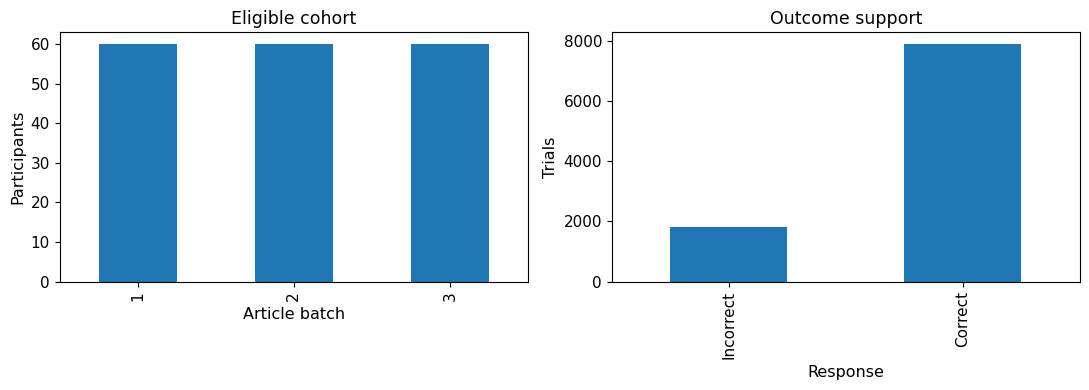

In [7]:
# ================== 06. Visualise Cohort and Class Support ===================

# ------------------ 1. Plot Participant and Outcome Support ------------------
fig, axes = plt.subplots(1,2,figsize=(11,4))
trials.groupby("article_batch").participant_id.nunique().plot.bar(ax=axes[0])
axes[0].set(xlabel="Article batch",ylabel="Participants",title="Eligible cohort")
trials.is_correct.value_counts().sort_index().rename(index={0:"Incorrect",1:"Correct"}).plot.bar(ax=axes[1])
axes[1].set(xlabel="Response",ylabel="Trials",title="Outcome support")

# --------------------------- 2. Save Cohort Figure ---------------------------
fig.tight_layout()
save_figure(fig,out_dir/"01_cohort_support.png")
plt.show()


**07. Save Cohort and Experimental Protocol**

Export the current source inventory, exclusion accounting, trial identities, participant assignments and support counts. No raw paragraph text or selected answers are published.

**Handoff to Notebook 02:** The executed stage produced six files in `output/`, including `01_trial_index.csv` and `01_participant_splits.csv`. Notebook 02 reads these tables and reconciles them with the original paragraph reports before feature extraction. Reuse the current tables rather than generating a new split. Feature extraction, association estimates and model evaluation are not results of this notebook.

In [8]:
# ================= 07. Save Cohort and Experimental Protocol =================

# ----------------------- 1. Save Current Cohort Tables -----------------------
for name, frame in {"01_source_inventory.csv":inventory,
                    "01_trial_exclusions.csv":exclusions,
                    "01_trial_index.csv":trials,
                    "01_participant_splits.csv":splits,
                    "01_split_support.csv":support}.items():
    frame.to_csv(out_dir/name,index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"01")


------------------------------------------------------------------------
Notebook 01
Files packaged: 6
  + 01_cohort_support.png
  + 01_participant_splits.csv
  + 01_source_inventory.csv
  + 01_split_support.csv
  + 01_trial_exclusions.csv
  + 01_trial_index.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_01_Outputs.zip
